# 03 — Segmentation des clients

**Projet :** Segmentation et score d'appétence d'une base clients retail
**Auteure :** Niya C. Danielle Ouattara

**Objectif :** regrouper les clients en quatre à cinq segments homogènes, compréhensibles et actionnables par les équipes marketing.

| Étape | Contenu |
|---|---|
| 1 | Import et traitement des profils incohérents |
| 2 | Choix des variables |
| 3 | Standardisation |
| 4 | Choix du nombre de segments (méthode du coude, score de silhouette) |
| 5 | Segmentation par k-means |
| 6 | Portrait des segments |
| 7 | Visualisation |
| 8 | Export |

**Méthode en une phrase :** k-means regroupe les clients qui se ressemblent le plus sur les variables choisies ; chaque segment est ensuite décrit et nommé à partir de ses caractéristiques moyennes.

## 1. Import et traitement des profils incohérents

In [1]:
import pandas as pd                                     # manipulation de tableaux
import numpy as np                                      # calculs numériques
import matplotlib.pyplot as plt                         # graphiques
from sklearn.preprocessing import StandardScaler        # standardisation des variables
from sklearn.cluster import KMeans                      # algorithme de segmentation k-means
from sklearn.metrics import silhouette_score            # mesure de la qualité d'une segmentation
from sklearn.decomposition import PCA                   # réduction à 2 dimensions, pour visualiser les segments

pd.set_option("display.max_columns", None)
plt.rcParams["axes.spines.top"] = False                 # graphiques plus lisibles, sans cadre en haut
plt.rcParams["axes.spines.right"] = False               # ni à droite

df = pd.read_csv("../outputs/clients_prepares.csv")     # base préparée par le notebook 01
print(df.shape)                                         # on attend 2 232 lignes

(2232, 49)


Le notebook 02 a mis en évidence des clients déclarant plus de 150 000 u.m. de revenu pour une dépense quasi nulle. Ce profil est incohérent avec le reste de la base et risque de créer un segment artificiel. **Choix :** ces clients sont écartés de la construction des segments, puis signalés à part.

In [2]:
incoherents = (df["Income"] > 150000) & (df["Depense_totale"] < 200)   # revenu très élevé ET dépense très faible
print(f"Clients incohérents écartés : {incoherents.sum()}")            # nombre de clients concernés
print(df.loc[incoherents, ["ID", "Income", "Depense_totale", "Achats_total"]])  # leur détail

base = df[~incoherents].copy()                           # ~ = « NON » : on garde tous les autres clients
print(f"Clients segmentés : {len(base)}")

Clients incohérents écartés : 4
         ID    Income  Depense_totale  Achats_total
614    1503  162397.0             107             1
652    5555  153924.0               6             0
1297   5336  157733.0              59             2
2128  11181  156924.0               8             0
Clients segmentés : 2228


## 2. Choix des variables

Les variables reprennent les axes qui différencient le plus les clients dans le notebook 02 :

| Axe | Variables |
|---|---|
| Valeur | Revenu, dépense totale, nombre d'achats |
| Foyer | Nombre d'enfants |
| Sensibilité prix | Part des achats en promotion |
| Canaux | Part web, part catalogue, visites web par mois |

Le panier moyen est écarté (valeurs extrêmes). La récence et les campagnes acceptées sont réservées au score d'appétence (notebook 04) : on segmente sur **qui sont les clients et comment ils achètent**, pas sur leur réponse aux campagnes.

In [3]:
variables = ["Income", "Depense_totale", "Achats_total", "Nb_enfants",      # liste des variables de segmentation
             "Part_promo", "Part_web", "Part_catalogue", "NumWebVisitsMonth"]
X = base[variables].copy()                               # tableau ne contenant que ces variables
X["Depense_totale"] = np.log1p(X["Depense_totale"])      # log1p = log(1 + x) : réduit l'écart entre petits et gros clients
X.describe().round(2)                                    # contrôle rapide des valeurs

,Income,Depense_totale,Achats_total,Nb_enfants,Part_promo,Part_web,Part_catalogue,NumWebVisitsMonth
count,2228.00,2228.00,2228.00,2228.00,2228.00,2228.00,2228.00,2228.00
mean,51752.16,5.62,12.56,0.95,0.24,0.33,0.16,5.33
std,20965.91,1.47,7.20,0.75,0.17,0.12,0.14,2.42
min,1730.00,1.79,0.00,0.00,0.00,0.00,0.00,0.00
25%,35409.00,4.25,6.00,0.00,0.08,0.25,0.00,3.00
50%,51400.50,5.99,12.00,1.00,0.20,0.33,0.15,6.00
75%,68130.00,6.95,18.00,1.00,0.33,0.40,0.25,7.00
max,160803.00,7.83,32.00,3.00,1.00,1.00,1.00,20.00


## 3. Standardisation

Les variables ne sont pas dans les mêmes unités : un revenu se compte en dizaines de milliers, une part en promotion entre 0 et 1. Sans correction, le revenu écraserait tout le reste. La standardisation ramène chaque variable à une moyenne de 0 et un écart-type de 1.

In [4]:
scaler = StandardScaler()                                # crée l'outil de standardisation
X_std = scaler.fit_transform(X)                          # calcule moyenne et écart-type, puis transforme les données
print(X_std.mean(axis=0).round(2))                       # contrôle : moyennes proches de 0
print(X_std.std(axis=0).round(2))                        # contrôle : écarts-types égaux à 1

[-0. -0.  0.  0. -0. -0.  0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1.]


## 4. Choix du nombre de segments

Deux indicateurs complémentaires :
- **Méthode du coude** : l'inertie mesure la dispersion à l'intérieur des segments. Elle baisse toujours quand on ajoute des segments ; on cherche le point où la baisse ralentit nettement.
- **Score de silhouette** (de -1 à 1) : plus il est élevé, mieux les segments sont séparés les uns des autres.

On croise ces indicateurs avec un critère métier : quatre à cinq segments, pour qu'ils restent actionnables.

In [5]:
resultats = []                                           # liste vide qui recevra les résultats
for k in range(2, 9):                                    # on teste de 2 à 8 segments
    modele = KMeans(n_clusters=k, n_init=20, random_state=42)   # n_init=20 : 20 essais, on garde le meilleur ; random_state fixe le hasard
    etiquettes = modele.fit_predict(X_std)               # entraîne le modèle et attribue un segment à chaque client
    resultats.append({"k": k,                            # on enregistre pour chaque k :
                      "inertie": modele.inertia_,        # l'inertie (dispersion interne)
                      "silhouette": silhouette_score(X_std, etiquettes)})   # et le score de silhouette
resultats = pd.DataFrame(resultats).set_index("k")       # transforme la liste en tableau
resultats.round(3)

,inertie,silhouette
k,,
2,9996.904,0.380
3,8358.437,0.277
4,7383.117,0.237
5,6748.539,0.225
6,6332.956,0.215
7,5944.469,0.218
8,5618.452,0.214


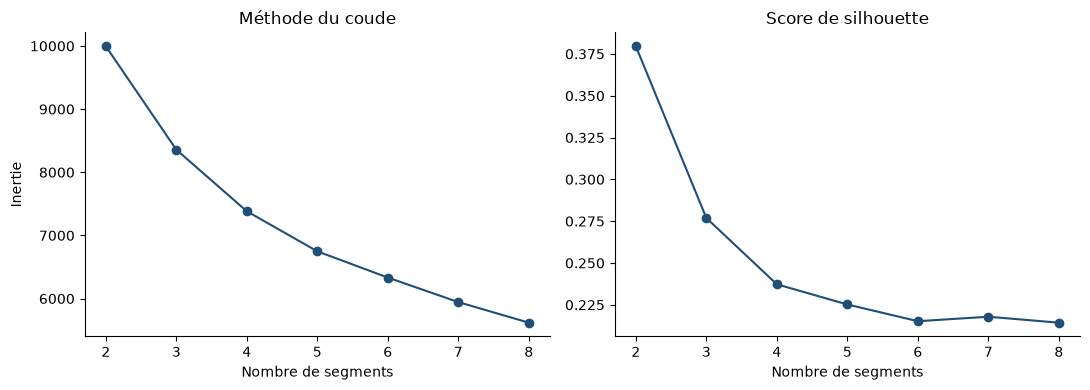

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))          # deux graphiques côte à côte
axes[0].plot(resultats.index, resultats["inertie"], marker="o", color="#1F4E79")
axes[0].set_title("Méthode du coude")
axes[0].set_xlabel("Nombre de segments")
axes[0].set_ylabel("Inertie")
axes[1].plot(resultats.index, resultats["silhouette"], marker="o", color="#1F4E79")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("Nombre de segments")
plt.tight_layout()
plt.savefig("../outputs/figures/03_choix_k.png", dpi=150)
plt.show()

> **Justification :** le score de silhouette est le plus élevé pour 2 segments (0,38), mais une segmentation en deux groupes ne ferait que séparer les gros et les petits clients, sans valeur opérationnelle. L'inertie baisse nettement jusqu'à 4 segments, puis plus lentement : c'est le coude. À 4 segments, la silhouette (0,24) reste proche de celle obtenue à 5 (0,23), pour des groupes plus lisibles et d'effectifs équilibrés (de 21 à 28 % de la base). Ce niveau de silhouette est courant pour des données de comportement d'achat, où les profils se chevauchent naturellement. 4 segments sont donc retenus.

In [7]:
K_RETENU = 4                                             # nombre de segments retenu : à ajuster après lecture des graphiques

## 5. Segmentation par k-means

In [8]:
kmeans = KMeans(n_clusters=K_RETENU, n_init=20, random_state=42)   # modèle final
base["Segment"] = kmeans.fit_predict(X_std)              # numéro de segment (0, 1, 2…) attribué à chaque client
print(base["Segment"].value_counts().sort_index())       # effectif de chaque segment

Segment
0    459
1    544
2    612
3    613
Name: count, dtype: int64


## 6. Portrait des segments

In [9]:
portrait = (base.groupby("Segment")                      # un groupe par segment
            .agg(nb_clients=("ID", "count"),             # effectif
                 age=("Age", "median"),                  # âge médian
                 revenu=("Income", "median"),            # revenu médian
                 enfants=("Nb_enfants", "mean"),         # nombre moyen d'enfants
                 depense=("Depense_totale", "median"),   # dépense médiane sur deux ans
                 achats=("Achats_total", "median"),      # nombre médian d'achats
                 part_promo=("Part_promo", "mean"),      # part moyenne des achats en promotion
                 part_web=("Part_web", "mean"),          # part moyenne des achats sur le web
                 part_catalogue=("Part_catalogue", "mean"),   # part moyenne des achats par catalogue
                 visites_web=("NumWebVisitsMonth", "median"),  # visites web par mois
                 recence=("Recency", "median"),          # jours depuis le dernier achat
                 campagnes=("Nb_campagnes_acceptees", "mean"),  # campagnes déjà acceptées (moyenne)
                 taux_reponse=("Response", "mean")))     # taux de réponse à la dernière campagne
portrait["part_base"] = portrait["nb_clients"] / portrait["nb_clients"].sum()          # poids dans la base
portrait["part_ca"] = (base.groupby("Segment")["Depense_totale"].sum()                 # poids dans le chiffre d'affaires
                       / base["Depense_totale"].sum())
portrait.round(2)

,nb_clients,age,revenu,enfants,depense,achats,part_promo,part_web,part_catalogue,visites_web,recence,campagnes,taux_reponse,part_base,part_ca
Segment,,,,,,,,,,,,,,,
0,459,44.0,40211.0,1.80,139.0,7.0,0.48,0.41,0.11,7.0,49.0,0.11,0.16,0.21,0.07
1,544,47.0,75809.5,0.19,1315.0,19.0,0.07,0.24,0.32,2.0,53.5,0.66,0.26,0.24,0.53
2,612,48.0,60063.0,0.94,740.5,17.0,0.16,0.38,0.17,6.0,49.0,0.34,0.13,0.27,0.37
3,613,40.0,31163.0,1.00,47.0,5.0,0.29,0.30,0.06,7.0,49.0,0.08,0.07,0.28,0.03


In [10]:
categories = ["Part_Wines", "Part_Meat", "Part_Gold", "Part_Fish", "Part_Sweet", "Part_Fruits"]  # parts par catégorie
base.groupby("Segment")[categories].mean().round(2)      # panier type de chaque segment

,Part_Wines,Part_Meat,Part_Gold,Part_Fish,Part_Sweet,Part_Fruits
Segment,,,,,,
0,0.48,0.24,0.15,0.06,0.04,0.04
1,0.44,0.33,0.06,0.07,0.05,0.05
2,0.58,0.20,0.09,0.05,0.04,0.04
3,0.34,0.24,0.18,0.10,0.07,0.07



| Segment | Nom | Portrait |
|---|---|---|
| 0 | Familles chasseuses de promotions | Foyers de près de deux enfants aux revenus modestes (40 000 u.m.), qui achètent presque un produit sur deux en promotion et utilisent beaucoup le site ; faible dépense, mais réceptifs aux offres (16 % de réponse). |
| 1 | Clients premium | Foyers aisés (76 000 u.m.) presque sans enfant, qui dépensent le plus (1 315 u.m.), achètent peu en promotion, privilégient le catalogue et la viande, et répondent le plus aux campagnes (26 %). |
| 2 | Réguliers amateurs de vin | Clients aux revenus intermédiaires (60 000 u.m.), un enfant en moyenne, qui achètent souvent sur tous les canaux ; le vin représente 58 % de leur panier. |
| 3 | Petits budgets occasionnels | Clients plus jeunes (40 ans) aux revenus modestes (31 000 u.m.), qui achètent rarement et peu (47 u.m. sur deux ans) et répondent très peu aux campagnes (7 %). |

In [11]:
noms_segments = {0: "Familles chasseuses de promotions",   # noms métier attribués après lecture des portraits
                 1: "Clients premium",
                 2: "Réguliers amateurs de vin",
                 3: "Petits budgets occasionnels"}
base["Nom_segment"] = base["Segment"].map(noms_segments)   # ajoute le nom en clair à chaque client
base["Nom_segment"].value_counts()                         # effectif de chaque segment, avec son nom

Nom_segment
Petits budgets occasionnels          613
Réguliers amateurs de vin            612
Clients premium                      544
Familles chasseuses de promotions    459
Name: count, dtype: int64

## 7. Visualisation

Pour représenter 8 variables sur un graphique en deux dimensions, on utilise une analyse en composantes principales (ACP) : elle résume les variables en deux axes qui conservent l'essentiel de l'information.

Information conservée : 72%


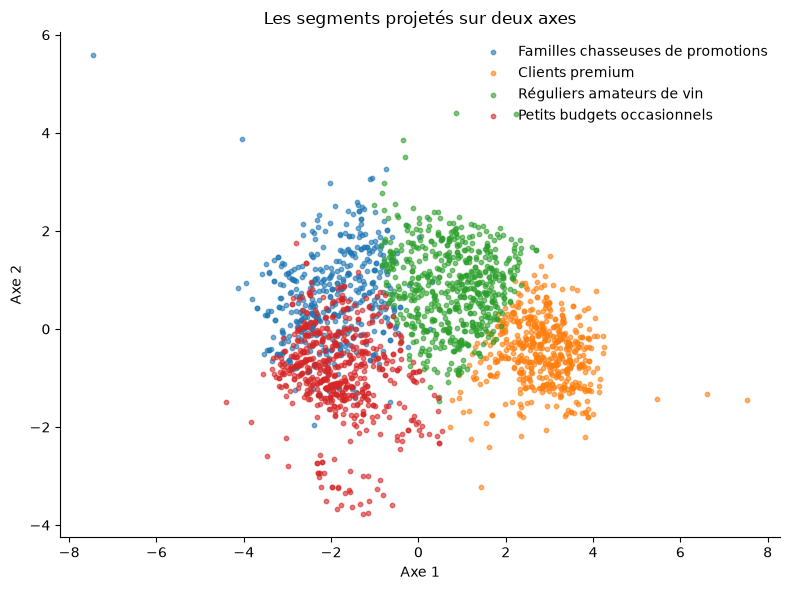

In [12]:
acp = PCA(n_components=2, random_state=42)               # réduction à 2 axes
coords = acp.fit_transform(X_std)                        # coordonnées de chaque client sur ces 2 axes
print(f"Information conservée : {acp.explained_variance_ratio_.sum():.0%}")   # part de l'information résumée par les 2 axes

fig, ax = plt.subplots(figsize=(8, 6))
for seg in sorted(base["Segment"].unique()):             # un nuage de points par segment
    masque = (base["Segment"] == seg).values             # clients du segment
    ax.scatter(coords[masque, 0], coords[masque, 1], s=10, alpha=0.6,
               label=noms_segments.get(seg, f"Segment {seg}"))
ax.set_title("Les segments projetés sur deux axes")
ax.set_xlabel("Axe 1")
ax.set_ylabel("Axe 2")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("../outputs/figures/03_segments_acp.png", dpi=150)
plt.show()

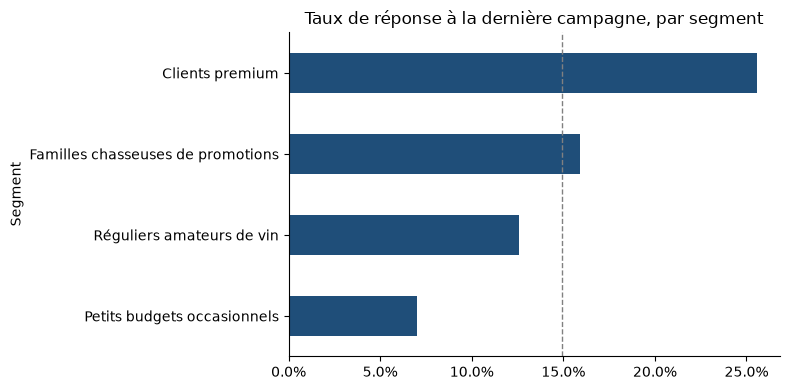

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
(portrait["taux_reponse"]                                # taux de réponse de chaque segment
 .rename(index=noms_segments)                            # remplace les numéros par les noms
 .sort_values()
 .plot(kind="barh", ax=ax, color="#1F4E79"))
ax.axvline(base["Response"].mean(), color="grey", linestyle="--", linewidth=1)   # ligne verticale : taux moyen de la base
ax.set_title("Taux de réponse à la dernière campagne, par segment")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig("../outputs/figures/03_reponse_segments.png", dpi=150)
plt.show()

## 8. Export

In [14]:
df["Segment"] = base["Segment"]                          # rattache le segment à la base complète (les incohérents restent vides)
df["Nom_segment"] = base["Nom_segment"]
df["Nom_segment"] = df["Nom_segment"].fillna("Non classé (profil incohérent)")   # libellé pour les clients écartés
df.to_csv("../outputs/clients_segmentes.csv", index=False)   # base utilisée par les notebooks 04 et 05 et par le dashboard
print(df["Nom_segment"].value_counts())

Nom_segment
Petits budgets occasionnels          613
Réguliers amateurs de vin            612
Clients premium                      544
Familles chasseuses de promotions    459
Non classé (profil incohérent)         4
Name: count, dtype: int64


## Synthèse

**4 segments retenus** sur 2 228 clients (4 clients au profil incohérent écartés).

| Segment | Part de la base | Part du chiffre d'affaires | Taux de réponse |
|---|---|---|---|
| Clients premium | 24 % | 53 % | 26 % |
| Réguliers amateurs de vin | 27 % | 37 % | 13 % |
| Familles chasseuses de promotions | 21 % | 7 % | 16 % |
| Petits budgets occasionnels | 28 % | 3 % | 7 % |

- **Les clients premium sont le cœur de la valeur** : un quart de la base réalise plus de la moitié du chiffre d'affaires, et c'est aussi le segment le plus réceptif aux campagnes.
- **Les réguliers amateurs de vin** forment le deuxième pilier (37 % du chiffre d'affaires) ; ils répondent peu aux campagnes actuelles, ce qui suggère des offres mieux ciblées sur le vin.
- **Les familles chasseuses de promotions** dépensent peu mais répondent au-dessus de la moyenne : elles sont sensibles aux bonnes affaires, pas indifférentes au marketing.
- **Les petits budgets occasionnels** pèsent 28 % de la base pour 3 % du chiffre d'affaires et répondent très peu : les inclure dans chaque campagne coûte cher pour un faible retour.